# Checkpoint 05: Tích Hợp Toàn Diện Các Giải Pháp Nâng Cấp (Combined Enhancements)

Nghiên cứu: Nâng cao hiệu năng mô hình phát hiện phát ngôn thù ghét trên mạng xã hội tiếng Việt (ViHSD).

Mục tiêu khoa học:
1. Tích hợp đồng thời 4 giải pháp tối ưu hóa độc lập đã được chứng minh hiệu quả từ các Checkpoint trước trên nền tảng kiến trúc `vinai/phobert-base`:
   - **Tiền xử lý mạng xã hội chuyên sâu (CP03):** Áp dụng `ViHSDPreprocessor` (chuẩn hóa teencode 412 quy tắc, ánh xạ emoji 2 pha, thu gọn ký tự, tách từ ghép PyVi, bảo tồn đại từ nhân xưng và từ phủ định).
   - **Hàm mất mát Weighted Focal Loss (CP01 + CP02):** Kết hợp vector trọng số lớp làm mịn căn bậc hai $\alpha$ (Smoothed Class Weights) và cơ chế điều chế mẫu khó động $\gamma = 1.5$:
     $$\mathcal{L}_{WFL} = -\alpha_{y_i} (1 - p_{i, y_i})^\gamma \log(p_{i, y_i})$$
   - **Mở rộng ngữ cảnh (CP04):** `max_length = 256` bao phủ trọn vẹn ngữ cảnh bình luận.
   - **Tối ưu hóa huấn luyện nâng cao (CP04):** Phân tầng tốc độ học ($2 \times 10^{-5}$ roberta / $1 \times 10^{-4}$ classifier), Cosine Annealing with Warmup, 8 epochs, batch size 16 + gradient accumulation 2, Early Stopping patience = 2.
2. Đánh giá hiệu ứng cộng hưởng tích cực giữa tiền xử lý ngôn ngữ, cân bằng phân bố lớp và tối ưu hóa hội tụ.
3. Xuất đầy đủ 4 tệp Mandatory Artifacts cùng biểu đồ Learning Curves vào `outputs/checkpoint05/`.

Ghi chú: Toàn bộ mã nguồn định nghĩa bộ tiền xử lý, Dataset, hàm mất mát Weighted Focal Loss, Optimizer phân tầng và đánh giá được tích hợp 100% trong notebook để chạy độc lập trên Google Colab.

In [1]:
import os
import sys

# Thiết lập môi trường làm việc và kết nối Google Drive trên Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    project_dir = '/content/drive/MyDrive/NLP_PhoBert_ViHSD'
except ImportError:
    project_dir = os.path.abspath('..')

checkpoints_dir = os.path.join(project_dir, 'checkpoints', 'checkpoint05')
outputs_dir = os.path.join(project_dir, 'outputs', 'checkpoint05')

os.makedirs(checkpoints_dir, exist_ok=True)
os.makedirs(outputs_dir, exist_ok=True)

print(f'Thư mục dự án: {project_dir}')
print(f'Thư mục lưu checkpoint: {checkpoints_dir}')
print(f'Thư mục lưu kết quả: {outputs_dir}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Thư mục dự án: /content/drive/MyDrive/NLP_PhoBert_ViHSD
Thư mục lưu checkpoint: /content/drive/MyDrive/NLP_PhoBert_ViHSD/checkpoints/checkpoint05
Thư mục lưu kết quả: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint05


In [2]:
# Cài đặt các thư viện cần thiết trên môi trường Google Colab
!pip install -q pyvi transformers accelerate scikit-learn seaborn matplotlib pandas numpy torch

In [3]:
# Thiết lập hạt giống ngẫu nhiên cố định để đảm bảo tính tái lập thực nghiệm
random_seed = 456  # Cố định ngẫu nhiên cho lượt chạy mới; output hiện lưu thuộc lượt cũ.

import os
import random
import numpy as np
import torch

os.environ['PYTHONHASHSEED'] = str(random_seed)
random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed(random_seed)
    torch.cuda.manual_seed_all(random_seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print(f'Thiết lập random seed thành công: {random_seed}')

Thiết lập random seed thành công: 456


## 1. Nạp Tập Dữ Liệu Thô và Kiểm Tra Trước Xử Lý (Pre-pipeline Verification)

In [4]:
# Cấu hình đường dẫn tập dữ liệu
data_dir = 'data' if os.path.exists('data/train.csv') else os.path.join(project_dir, 'data')
train_path = os.path.join(data_dir, 'train.csv')
dev_path = os.path.join(data_dir, 'dev.csv')
test_path = os.path.join(data_dir, 'test.csv')

import pandas as pd

train_raw = pd.read_csv(train_path)
dev_raw = pd.read_csv(dev_path)
test_raw = pd.read_csv(test_path)

assert len(train_raw) == 24048, f'Số lượng mẫu train không khớp: {len(train_raw)}'
assert len(dev_raw) == 2672, f'Số lượng mẫu dev không khớp: {len(dev_raw)}'
assert len(test_raw) == 6680, f'Số lượng mẫu test không khớp: {len(test_raw)}'

print('Kiểm tra tập dữ liệu thô trước xử lý:')
print(f'- Train: {len(train_raw)} mẫu, null: {train_raw["free_text"].isna().sum()}')
print(f'- Dev:   {len(dev_raw)} mẫu, null: {dev_raw["free_text"].isna().sum()}')
print(f'- Test:  {len(test_raw)} mẫu, null: {test_raw["free_text"].isna().sum()}')

Kiểm tra tập dữ liệu thô trước xử lý:
- Train: 24048 mẫu, null: 2
- Dev:   2672 mẫu, null: 0
- Test:  6680 mẫu, null: 0


## 2. Tiền Xử Lý và Chuẩn Hóa Dữ Liệu Chuyên Sâu (ViHSDPreprocessor)

In [5]:
import re
import unicodedata
import numpy as np
import pandas as pd

try:
    from pyvi import ViTokenizer
except ImportError:
    ViTokenizer = None


class ViHSDPreprocessor:

    def __init__(self, teencode_path, emoji_path, segmenter=None):
        self.segmenter = segmenter
        self.teencode_dict = self._load_teencode_dict(teencode_path)
        self.emoji_dict = self._load_emoji_dict(emoji_path)

        self.url_re          = re.compile(r'https?://\S+|www\.\S+')
        self.ws_re           = re.compile(r'\s+')
        self.ctrl_re         = re.compile(r'[\r\n\t]+')
        self.lengthen_re     = re.compile(r'([a-zA-Z\u00C0-\u1EF9])\1{2,}', re.IGNORECASE)

        tc_keys = [re.escape(k) for k in sorted(self.teencode_dict, key=len, reverse=True)]
        self.tc_re = re.compile(r'\b(' + '|'.join(tc_keys) + r')\b', re.IGNORECASE) if tc_keys else None

        em_keys = [re.escape(k) for k in sorted(self.emoji_dict, key=len, reverse=True)]
        self.em_re = re.compile('(' + '|'.join(em_keys) + ')') if em_keys else None

    def _load_teencode_dict(self, path):
        df = pd.read_csv(path)
        k = 'teencode'     if 'teencode'     in df.columns else df.columns[0]
        v = 'replacement'  if 'replacement'  in df.columns else ('standard' if 'standard' in df.columns else df.columns[1])
        return dict(zip(df[k].astype(str).str.strip().str.lower(),
                        df[v].astype(str).str.strip().str.lower()))

    def _load_emoji_dict(self, path):
        df = pd.read_csv(path)
        k = 'emoji'       if 'emoji'       in df.columns else df.columns[0]
        v = 'replacement' if 'replacement' in df.columns else ('meaning' if 'meaning' in df.columns else df.columns[1])
        return dict(zip(df[k].astype(str).str.strip(),
                        df[v].astype(str).str.strip()))

    def _clean(self, text):
        text = unicodedata.normalize('NFC', text)
        text = self.url_re.sub(' ', text)
        text = self.ctrl_re.sub(' ', text)
        return self.ws_re.sub(' ', text).strip()

    def _map_emojis(self, text):
        if self.em_re is None:
            return text
        text = self.em_re.sub(lambda m: f' {self.emoji_dict.get(m.group(0), "")} ', text)
        return self.ws_re.sub(' ', text).strip()

    def _norm_teencode(self, text):
        if self.tc_re is None:
            return text
        return self.tc_re.sub(lambda m: self.teencode_dict.get(m.group(0).lower(), m.group(0)), text)

    def _reduce_lengthen(self, text):
        return self.lengthen_re.sub(r'\1', text)

    def _segment(self, text):
        if self.segmenter is not None:
            try:
                out = self.segmenter.word_segment(text)
                return ' '.join(out).strip() if isinstance(out, list) else str(out).strip()
            except Exception:
                pass
        return ViTokenizer.tokenize(text) if ViTokenizer else text

    def transform_text(self, text, lowercased=False):
        if not isinstance(text, str):
            text = str(text) if text is not None else ''
        if not text.strip():
            return ''
        text = self._clean(text)
        text = self._map_emojis(text)
        text = self._norm_teencode(text)
        text = self._reduce_lengthen(text)
        if text.strip():
            text = self._segment(text)
        if lowercased:
            text = text.lower()
        return self.ws_re.sub(' ', text).strip()

    def transform_dataset(self, df, text_col='free_text', label_col='label_id', lowercased=False):
        df = df.dropna(subset=[text_col, label_col]).copy()
        df[label_col] = df[label_col].astype(int)
        texts, indices = [], []
        for idx, row in df.iterrows():
            t = self.transform_text(row[text_col], lowercased=lowercased)
            if t:
                texts.append(t)
                indices.append(idx)
        return texts, df.loc[indices, label_col].to_numpy()

    @staticmethod
    def _norm_key(text):
        """Chuẩn hóa để so khớp trùng lặp: NFC + lowercase + bỏ dấu câu + chuẩn hóa khoảng trắng."""
        if not isinstance(text, str):
            text = str(text) if text is not None else ''
        text = unicodedata.normalize('NFC', text).lower()
        text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
        text = re.sub(r'[^\w\s]', ' ', text)
        return re.sub(r'\s+', ' ', text).strip()

    @classmethod
    def clean_and_deduplicate(cls, train_df, dev_df=None, test_df=None,
                               text_col='free_text', label_col='label_id',
                               drop_conflicting=True, verbose=True):
        """Loại bỏ data leakage, label conflict và duplicate khỏi tập train."""
        df = train_df.dropna(subset=[text_col, label_col]).copy()
        df[label_col] = df[label_col].astype(int)
        df['_k'] = df[text_col].apply(cls._norm_key)
        n0 = len(df)

        # 1. Loại bỏ leakage (train ∩ dev/test)
        eval_keys = set()
        if dev_df is not None:
            eval_keys |= set(dev_df[text_col].dropna().apply(cls._norm_key))
        if test_df is not None:
            eval_keys |= set(test_df[text_col].dropna().apply(cls._norm_key))
        df = df[~df['_k'].isin(eval_keys)]
        n1 = len(df)

        # 2. Loại bỏ label conflict (cùng văn bản, khác nhãn)
        conflict_keys = set(
            df.groupby('_k')[label_col].nunique().pipe(lambda s: s[s > 1]).index
        )
        if drop_conflicting:
            df = df[~df['_k'].isin(conflict_keys)]
        else:
            df = df.drop_duplicates(subset=['_k'], keep='first')
        n2 = len(df)

        # 3. Khử trùng lặp nội bộ
        df = df.drop_duplicates(subset=['_k'], keep='first')
        n3 = len(df)

        if verbose:
            print(f'  Leakage removed   : {n0 - n1:>5,}  ({n0:,} → {n1:,})')
            print(f'  Conflict removed  : {n1 - n2:>5,}  ({n1:,} → {n2:,})')
            print(f'  Duplicate removed : {n2 - n3:>5,}  ({n2:,} → {n3:,})')
            print(f'  Final train size  : {n3:>5,}')

            label_names = {0: 'clean', 1: 'offensive', 2: 'hate'}
            before = train_df.dropna(subset=[label_col])[label_col].astype(int).value_counts().sort_index()
            after  = df[label_col].value_counts().sort_index()
            print(f'  {"Label":<12} {"Before":>8} {"After":>8} {"Δ":>7}')
            for lbl, name in label_names.items():
                b, a = before.get(lbl, 0), after.get(lbl, 0)
                print(f'  {name:<12} {b:>8,} {a:>8,} {a-b:>+7,}')

        return df.drop(columns=['_k'])

    @classmethod
    def verify_no_leakage(cls, train_df, dev_df=None, test_df=None,
                           text_col='free_text'):
        """Assert rằng train không còn overlap với dev/test và không có duplicate nội bộ."""
        train_keys = set(train_df[text_col].dropna().apply(cls._norm_key))

        if dev_df is not None:
            overlap = train_keys & set(dev_df[text_col].dropna().apply(cls._norm_key))
            assert not overlap, f'Leakage: {len(overlap)} mẫu train còn trong Dev'

        if test_df is not None:
            overlap = train_keys & set(test_df[text_col].dropna().apply(cls._norm_key))
            assert not overlap, f'Leakage: {len(overlap)} mẫu train còn trong Test'

        _df = train_df[text_col].dropna().apply(cls._norm_key)
        assert not _df.duplicated().any(), 'Còn duplicate nội bộ trong train'

        print('Không còn leakage và duplicate trong tập train.')


## 3. Khử Trùng Lặp, Triệt Tiêu Rò Rỉ Dữ Liệu (Data Leakage) và Tiền Xử Lý Văn Bản

Khảo sát và xử lý các vấn đề chất lượng dữ liệu cốt lõi trong tập ViHSD:
1. **Triệt tiêu rò rỉ dữ liệu (Data Leakage Elimination):** Loại bỏ hoàn toàn các câu trong tập Train có mặt trong tập Dev hoặc Test để đảm bảo mô hình không học vẹt dữ liệu đánh giá, bảo toàn tính khách quan trong đánh giá tổng quát hóa.
2. **Khử nhiễu nhãn mâu thuẫn (Label Noise Resolution):** Loại bỏ các văn bản giống hệt nhau nhưng bị gán nhiều nhãn khác nhau (0, 1, 2) do bất đồng giữa các người gán nhãn, ngăn ngừa gradient đối nghịch làm mất ổn định hàm mất mát.
3. **Khử trùng lặp nội bộ (Deduplication):** Giữ lại duy nhất một bản ghi đại diện cho các mẫu trùng lặp cùng nhãn để tránh thiên lệch tần suất.
4. **Chuẩn hóa ngôn ngữ mạng xã hội:** Áp dụng  (Teencode 412 quy tắc, Emoji 2 pha, thu gọn lặp ký tự và phân đoạn từ PyVi).

In [6]:
teencode_path = os.path.join(data_dir, 'teencode.csv')
emoji_path    = os.path.join(data_dir, 'emojis.csv')

# 1. Khử trùng lặp và loại bỏ data leakage khỏi tập train
print('=== Deduplication & Leakage Elimination ===')
train_clean_df = ViHSDPreprocessor.clean_and_deduplicate(
    train_df=train_raw, dev_df=dev_raw, test_df=test_raw,
    text_col='free_text', label_col='label_id',
    drop_conflicting=True, verbose=True
)

# 2. Xác minh không còn leakage
ViHSDPreprocessor.verify_no_leakage(
    train_df=train_clean_df, dev_df=dev_raw, test_df=test_raw
)

# 3. Tiền xử lý văn bản trên ba tập
preprocessor = ViHSDPreprocessor(teencode_path=teencode_path, emoji_path=emoji_path)
print('\n=== Preprocessing ===')

train_X, train_y = preprocessor.transform_dataset(train_clean_df)
dev_X,   dev_y   = preprocessor.transform_dataset(dev_raw)
test_X,  test_y  = preprocessor.transform_dataset(test_raw)

assert len(train_X) == len(train_y)
assert len(dev_X)   == len(dev_y)
assert len(test_X)  == len(test_y)
assert all(t.strip() for t in train_X), 'Tồn tại văn bản rỗng trong train_X'

print(f'  Train : {len(train_X):,} mẫu')
print(f'  Dev   : {len(dev_X):,} mẫu')
print(f'  Test  : {len(test_X):,} mẫu')


=== Deduplication & Leakage Elimination ===
  Leakage removed   : 1,741  (24,046 → 22,305)
  Conflict removed  :   238  (22,305 → 22,067)
  Duplicate removed : 1,396  (22,067 → 20,671)
  Final train size  : 20,671
  Label          Before    After       Δ
  clean          19,886   16,927  -2,959
  offensive       1,606    1,395    -211
  hate            2,556    2,349    -207
Không còn leakage và duplicate trong tập train.

=== Preprocessing ===
  Train : 20,671 mẫu
  Dev   : 2,672 mẫu
  Test  : 6,680 mẫu


## 4. Định Nghĩa Lớp BuildDataset và Mã Hóa Chuỗi Mở Rộng (max_length = 256)

In [7]:
pretrained_model_name = 'vinai/phobert-base'
max_seq_length = 256

import torch
from transformers import AutoTokenizer


class BuildDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)


print(f'Khởi tạo Tokenizer: {pretrained_model_name} (use_fast=False, max_length={max_seq_length})')
tokenizer = AutoTokenizer.from_pretrained(pretrained_model_name, use_fast=False)

train_encodings = tokenizer(train_X, truncation=True, padding=True, max_length=max_seq_length)
dev_encodings = tokenizer(dev_X, truncation=True, padding=True, max_length=max_seq_length)
test_encodings = tokenizer(test_X, truncation=True, padding=True, max_length=max_seq_length)

train_dataset = BuildDataset(train_encodings, train_y)
dev_dataset = BuildDataset(dev_encodings, dev_y)
test_dataset = BuildDataset(test_encodings, test_y)

print(f'Kích thước tập train sau mã hóa: {len(train_dataset)}')
print(f'Kích thước tập dev sau mã hóa:   {len(dev_dataset)}')
print(f'Kích thước tập test sau mã hóa:  {len(test_dataset)}')

Khởi tạo Tokenizer: vinai/phobert-base (use_fast=False, max_length=256)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Kích thước tập train sau mã hóa: 20671
Kích thước tập dev sau mã hóa:   2672
Kích thước tập test sau mã hóa:  6680


## 5. Tính Toán Vector Trọng Số Smoothed Class Weights và Định Nghĩa Weighted Focal Loss

Hàm mất mát tích hợp Weighted Focal Loss:
$$\mathcal{L}_{WFL}(p_t) = -\alpha_t (1 - p_t)^\gamma \log(p_t), \quad \gamma = 1.5$$
Với vector $\alpha$ là trọng số làm mịn căn bậc hai được tính từ phân bố tập huấn luyện.

In [8]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW
from transformers import Trainer, get_cosine_schedule_with_warmup


def compute_smoothed_class_weights(labels):
    labels = np.asarray(labels, dtype=int)
    total_samples = len(labels)
    classes, counts = np.unique(labels, return_counts=True)
    counts_float = counts.astype(np.float64)
    raw_smoothed = np.sqrt(total_samples / counts_float)
    w_smoothed = raw_smoothed / np.mean(raw_smoothed)
    return torch.tensor(w_smoothed, dtype=torch.float32), dict(zip(classes, counts))


active_class_weights, class_counts = compute_smoothed_class_weights(train_y)
print(f'Vector alpha Smoothed Class Weights: {active_class_weights.tolist()}')


class WeightedFocalLoss(nn.Module):
    """Hàm mất mát kết hợp giữa Smoothed Class Weights (alpha) và Focal Loss (gamma = 1.5)."""

    def __init__(self, alpha=None, gamma=1.5, reduction='mean'):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha
        self.reduction = reduction

    def forward(self, logits, targets):
        ce_loss = F.cross_entropy(logits, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        modulating_factor = (1.0 - pt) ** self.gamma
        focal_loss = modulating_factor * ce_loss

        if self.alpha is not None:
            if isinstance(self.alpha, torch.Tensor):
                alpha_t = self.alpha.to(logits.device)[targets]
                focal_loss = alpha_t * focal_loss
            else:
                focal_loss = self.alpha * focal_loss

        return focal_loss.mean() if self.reduction == 'mean' else focal_loss


class CombinedOptimizedTrainer(Trainer):
    """Trainer tích hợp đồng thời Weighted Focal Loss, phân tầng tốc độ học và Cosine Warmup."""

    def __init__(self, *args, loss_fn=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.loss_fn = loss_fn if loss_fn is not None else WeightedFocalLoss()

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None, **kwargs):
        labels = inputs.get('labels')
        outputs = model(**inputs)
        logits = outputs.get('logits')
        loss = self.loss_fn(logits, labels)
        return (loss, outputs) if return_outputs else loss

    def create_optimizer_and_scheduler(self, num_training_steps: int):
        roberta_decay = [p for n, p in self.model.named_parameters() if 'roberta' in n and not any(nd in n for nd in ['bias', 'LayerNorm.weight'])]
        roberta_no_decay = [p for n, p in self.model.named_parameters() if 'roberta' in n and any(nd in n for nd in ['bias', 'LayerNorm.weight'])]
        classifier_decay = [p for n, p in self.model.named_parameters() if 'roberta' not in n and not any(nd in n for nd in ['bias', 'LayerNorm.weight'])]
        classifier_no_decay = [p for n, p in self.model.named_parameters() if 'roberta' not in n and any(nd in n for nd in ['bias', 'LayerNorm.weight'])]

        optimizer_grouped_parameters = [
            {'params': roberta_decay, 'lr': 2e-5, 'weight_decay': 0.01},
            {'params': roberta_no_decay, 'lr': 2e-5, 'weight_decay': 0.0},
            {'params': classifier_decay, 'lr': 1e-4, 'weight_decay': 0.01},
            {'params': classifier_no_decay, 'lr': 1e-4, 'weight_decay': 0.0},
        ]

        self.optimizer = AdamW(optimizer_grouped_parameters)
        warmup_steps = int(num_training_steps * 0.10)
        self.lr_scheduler = get_cosine_schedule_with_warmup(
            self.optimizer,
            num_warmup_steps=warmup_steps,
            num_training_steps=num_training_steps,
        )
        print(f'Đã khởi tạo Optimizer phân tầng với Weighted Focal Loss.')
        return self.optimizer, self.lr_scheduler

weighted_focal_loss_fn = WeightedFocalLoss(alpha=active_class_weights, gamma=1.5)
print('Đã khởi tạo WeightedFocalLoss(gamma=1.5, alpha=active_class_weights) thành công.')

Vector alpha Smoothed Class Weights: [0.4185382127761841, 1.4579344987869263, 1.1235272884368896]
Đã khởi tạo WeightedFocalLoss(gamma=1.5, alpha=active_class_weights) thành công.


## 6. Cấu Hình Siêu Tham Số Huấn Luyện và Dừng Sớm (Early Stopping)

In [9]:
num_labels = 3
num_epochs = 8
train_batch_size = 16
eval_batch_size = 16
gradient_accumulation_steps = 2
weight_decay = 0.01

import numpy as np
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from transformers import AutoModelForSequenceClassification, EarlyStoppingCallback, TrainingArguments


def compute_metrics_eval(eval_pred):
    predictions, labels = eval_pred
    preds = np.argmax(predictions, axis=-1)
    acc = accuracy_score(labels, preds)
    macro_p = precision_score(labels, preds, average='macro', zero_division=0)
    macro_r = recall_score(labels, preds, average='macro', zero_division=0)
    macro_f1 = f1_score(labels, preds, average='macro')
    micro_f1 = f1_score(labels, preds, average='micro')
    per_class_f1 = f1_score(labels, preds, average=None)
    return {
        'accuracy': acc,
        'macro_precision': macro_p,
        'macro_recall': macro_r,
        'macro_f1': macro_f1,
        'micro_f1': micro_f1,
        'f1_clean': per_class_f1[0] if len(per_class_f1) > 0 else 0.0,
        'f1_offensive': per_class_f1[1] if len(per_class_f1) > 1 else 0.0,
        'f1_hate': per_class_f1[2] if len(per_class_f1) > 2 else 0.0,
    }


model = AutoModelForSequenceClassification.from_pretrained(pretrained_model_name, num_labels=num_labels)

training_args = TrainingArguments(
    output_dir=checkpoints_dir,
    num_train_epochs=num_epochs,
    per_device_train_batch_size=train_batch_size,
    per_device_eval_batch_size=eval_batch_size,
    gradient_accumulation_steps=gradient_accumulation_steps,
    weight_decay=weight_decay,
    do_eval=True,
    eval_strategy='epoch',
    save_strategy='epoch',
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model='macro_f1',
    greater_is_better=True,
    fp16=torch.cuda.is_available(),
    logging_steps=50,
    seed=random_seed,
)

trainer = CombinedOptimizedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=dev_dataset,
    compute_metrics=compute_metrics_eval,
    loss_fn=weighted_focal_loss_fn,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

print('Khởi tạo CombinedOptimizedTrainer thành công cho Checkpoint 05.')

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Khởi tạo CombinedOptimizedTrainer thành công cho Checkpoint 05.


## 7. Huấn Luyện Mô Hình và Lưu Checkpoint Tối Ưu

In [10]:
print('Bắt đầu huấn luyện Checkpoint 05 (Combined Enhancements)...')
train_result = trainer.train()

save_model_dir = os.path.join(checkpoints_dir, 'final_model')
trainer.save_model(save_model_dir)
tokenizer.save_pretrained(save_model_dir)
print(f'Đã lưu mô hình tối ưu nhất tại: {save_model_dir}')

Bắt đầu huấn luyện Checkpoint 05 (Combined Enhancements)...


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Micro F1,F1 Clean,F1 Offensive,F1 Hate
1,0.374635,0.216002,0.847305,0.606503,0.524261,0.528033,0.847305,0.925005,0.126984,0.532110
2,0.302252,0.175292,0.845434,0.628883,0.655448,0.637650,0.845434,0.924751,0.418136,0.570064
3,0.200376,0.186818,0.837201,0.626626,0.685177,0.643891,0.837201,0.918791,0.437811,0.575071
4,0.127989,0.251413,0.863398,0.667117,0.672081,0.669474,0.863398,0.934340,0.480952,0.593128
5,0.078156,0.334523,0.864521,0.676337,0.653938,0.664575,0.864521,0.932971,0.463054,0.597701
6,0.046292,0.381636,0.868263,0.687531,0.667565,0.677089,0.868263,0.934482,0.486747,0.610039
7,0.034060,0.449562,0.868638,0.691611,0.672723,0.681772,0.868638,0.933545,0.496386,0.615385
8,0.012694,0.475398,0.866392,0.682505,0.662951,0.672110,0.866392,0.933333,0.480000,0.602996


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Đã lưu mô hình tối ưu nhất tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/checkpoints/checkpoint05/final_model


## 8. Đánh Giá Trên Tập Test Độc Lập

In [11]:
class_names = ['clean', 'offensive', 'hate']

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score


def evaluate_predictions(y_true, y_pred, class_names=None):
    if class_names is None:
        class_names = ['clean', 'offensive', 'hate']
    acc = accuracy_score(y_true, y_pred)
    macro_precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
    macro_recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
    macro_f1 = f1_score(y_true, y_pred, average='macro')
    micro_f1 = f1_score(y_true, y_pred, average='micro')
    per_class_precision = precision_score(y_true, y_pred, average=None, zero_division=0)
    per_class_recall = recall_score(y_true, y_pred, average=None, zero_division=0)
    per_class_f1 = f1_score(y_true, y_pred, average=None)
    cm = confusion_matrix(y_true, y_pred)
    report = classification_report(y_true, y_pred, target_names=class_names, digits=4)
    return {
        'accuracy': acc,
        'macro_precision': macro_precision,
        'macro_recall': macro_recall,
        'macro_f1': macro_f1,
        'micro_f1': micro_f1,
        'per_class_precision': {name: per_class_precision[i] for i, name in enumerate(class_names)},
        'per_class_recall': {name: per_class_recall[i] for i, name in enumerate(class_names)},
        'per_class_f1': {name: per_class_f1[i] for i, name in enumerate(class_names)},
        'confusion_matrix': cm,
        'classification_report': report,
    }


print('Thực hiện dự đoán với mô hình Checkpoint 05 trên tập kiểm tra...')
predictions_output = trainer.predict(test_dataset)
y_pred = np.argmax(predictions_output.predictions, axis=-1)
y_true = test_y

results = evaluate_predictions(y_true, y_pred, class_names=class_names)

print('=' * 60)
print('KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (CHECKPOINT 05)')
print('=' * 60)
print(f'Accuracy (Độ chính xác tổng thể):  {results["accuracy"]:.4f}')
print(f'Macro-Precision (Độ chuẩn xác):   {results["macro_precision"]:.4f}')
print(f'Macro-Recall (Độ nhạy):           {results["macro_recall"]:.4f}')
print(f'Macro-F1 Score (Chỉ số chính):    {results["macro_f1"]:.4f}')
print(f'Micro-F1 Score:                   {results["micro_f1"]:.4f}')
print('-' * 60)
print('Chi tiết theo từng lớp (Per-class):')
for cname in class_names:
    print(f'- {cname:9s}: Precision = {results["per_class_precision"][cname]:.4f}, Recall = {results["per_class_recall"][cname]:.4f}, F1 = {results["per_class_f1"][cname]:.4f}')
print('=' * 60)
print('Chi tiết Classification Report:')
print(results['classification_report'])

Thực hiện dự đoán với mô hình Checkpoint 05 trên tập kiểm tra...


KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (CHECKPOINT 05)
Accuracy (Độ chính xác tổng thể):  0.8737
Macro-Precision (Độ chuẩn xác):   0.6794
Macro-Recall (Độ nhạy):           0.6493
Macro-F1 Score (Chỉ số chính):    0.6626
Micro-F1 Score:                   0.8737
------------------------------------------------------------
Chi tiết theo từng lớp (Per-class):
- clean    : Precision = 0.9287, Recall = 0.9479, F1 = 0.9382
- offensive: Precision = 0.4539, Recall = 0.4550, F1 = 0.4544
- hate     : Precision = 0.6556, Recall = 0.5451, F1 = 0.5952
Chi tiết Classification Report:
              precision    recall  f1-score   support

       clean     0.9287    0.9479    0.9382      5548
   offensive     0.4539    0.4550    0.4544       444
        hate     0.6556    0.5451    0.5952       688

    accuracy                         0.8737      6680
   macro avg     0.6794    0.6493    0.6626      6680
weighted avg     0.8690    0.8737    0.8707      6680



## 9. Trực Quan Hóa Đồ Thị Tiến Trình Học và Ma Trận Nhầm Lẫn

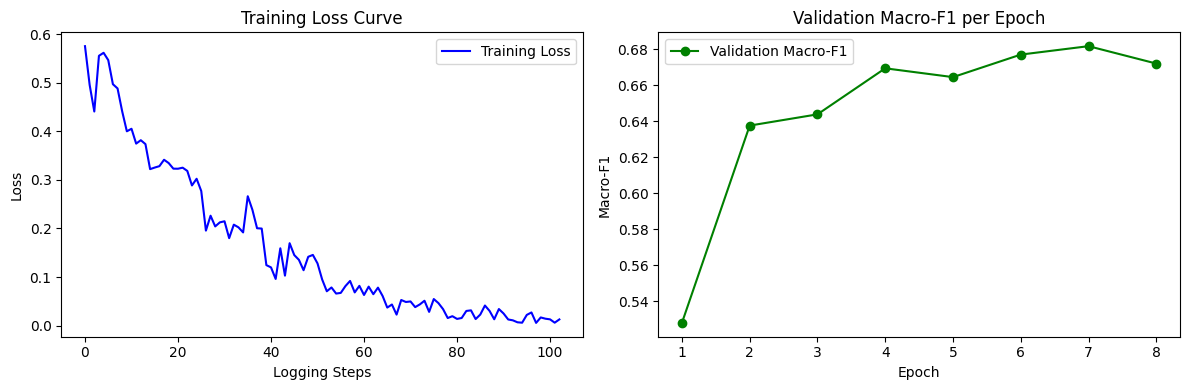

Đã lưu đồ thị học tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint05/learning_curves_checkpoint05.png


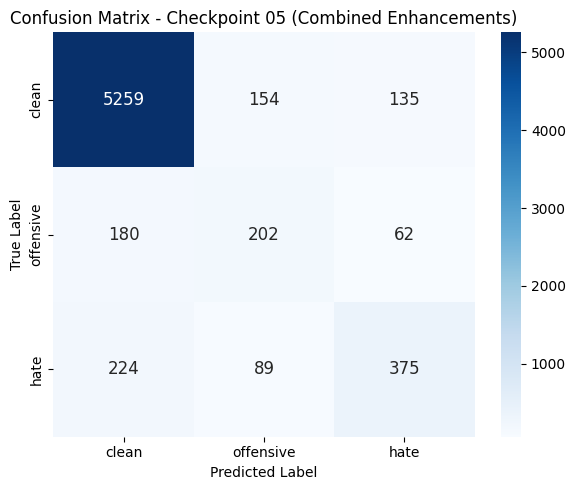

Đã lưu ma trận nhầm lẫn tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint05/confusion_matrix_checkpoint05.png


In [12]:
curves_output_path = os.path.join(outputs_dir, 'learning_curves_checkpoint05.png')
cm_output_path = os.path.join(outputs_dir, 'confusion_matrix_checkpoint05.png')

import matplotlib.pyplot as plt
import seaborn as sns

log_history = trainer.state.log_history
train_loss = [x['loss'] for x in log_history if 'loss' in x]
eval_f1 = [x['eval_macro_f1'] for x in log_history if 'eval_macro_f1' in x]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
if train_loss:
    ax1.plot(train_loss, label='Training Loss', color='blue')
    ax1.set_title('Training Loss Curve')
    ax1.set_xlabel('Logging Steps')
    ax1.set_ylabel('Loss')
    ax1.legend()
if eval_f1:
    ax2.plot(range(1, len(eval_f1) + 1), eval_f1, label='Validation Macro-F1', color='green', marker='o')
    ax2.set_title('Validation Macro-F1 per Epoch')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Macro-F1')
    ax2.legend()
plt.tight_layout()
plt.savefig(curves_output_path, dpi=300)
plt.show()
print(f'Đã lưu đồ thị học tại: {curves_output_path}')

df_cm = pd.DataFrame(results['confusion_matrix'], index=class_names, columns=class_names)
fig_cm, ax_cm = plt.subplots(figsize=(6, 5))
sns.heatmap(df_cm, annot=True, cmap='Blues', fmt='d', cbar=True, ax=ax_cm, annot_kws={'size': 12})
ax_cm.set_title('Confusion Matrix - Checkpoint 05 (Combined Enhancements)')
ax_cm.set_xlabel('Predicted Label')
ax_cm.set_ylabel('True Label')
plt.tight_layout()
plt.savefig(cm_output_path, dpi=300)
plt.show()
print(f'Đã lưu ma trận nhầm lẫn tại: {cm_output_path}')

## 10. Xuất Các Tệp Kết Quả Chuẩn Hóa (Mandatory Artifacts Export)

In [13]:
predictions_csv_path = os.path.join(outputs_dir, 'predictions.csv')
scores_csv_path = os.path.join(outputs_dir, 'evaluation_scores.csv')
report_csv_path = os.path.join(outputs_dir, 'classification_report.csv')
cm_csv_path = os.path.join(outputs_dir, 'confusion_matrix.csv')

test_ids = list(range(len(test_y)))

df_predictions = pd.DataFrame({
    'id': test_ids,
    'text': test_X,
    'ground_truth': y_true,
    'predicted_label': y_pred,
})
df_predictions.to_csv(predictions_csv_path, index=False, encoding='utf-8')
print(f'1. Đã xuất tệp dự đoán: {predictions_csv_path}')

df_cm = pd.DataFrame(results['confusion_matrix'], index=class_names, columns=class_names)
df_cm.index.name = 'true_label'
df_cm.to_csv(cm_csv_path)
print(f'2. Đã xuất tệp dữ liệu ma trận nhầm lẫn: {cm_csv_path}')

acc_val = round(float(results.get('accuracy', accuracy_score(y_true, y_pred))), 4)
macro_p_val = round(float(results.get('macro_precision', precision_score(y_true, y_pred, average='macro', zero_division=0))), 4)
macro_r_val = round(float(results.get('macro_recall', recall_score(y_true, y_pred, average='macro', zero_division=0))), 4)
per_class_p = results.get('per_class_precision', {name: round(precision_score(y_true, y_pred, average=None, zero_division=0)[i], 4) for i, name in enumerate(class_names)})
per_class_r = results.get('per_class_recall', {name: round(recall_score(y_true, y_pred, average=None, zero_division=0)[i], 4) for i, name in enumerate(class_names)})

scores_summary = {
    'metric': [
        'accuracy',
        'macro_precision',
        'macro_recall',
        'macro_f1',
        'micro_f1',
        'precision_clean',
        'recall_clean',
        'f1_clean',
        'precision_offensive',
        'recall_offensive',
        'f1_offensive',
        'precision_hate',
        'recall_hate',
        'f1_hate',
    ],
    'value': [
        acc_val,
        macro_p_val,
        macro_r_val,
        round(results['macro_f1'], 4),
        round(results['micro_f1'], 4),
        round(per_class_p['clean'], 4),
        round(per_class_r['clean'], 4),
        round(results['per_class_f1']['clean'], 4),
        round(per_class_p['offensive'], 4),
        round(per_class_r['offensive'], 4),
        round(results['per_class_f1']['offensive'], 4),
        round(per_class_p['hate'], 4),
        round(per_class_r['hate'], 4),
        round(results['per_class_f1']['hate'], 4),
    ],
}
df_scores = pd.DataFrame(scores_summary)
df_scores.to_csv(scores_csv_path, index=False)
print(f'3. Đã xuất tệp điểm số tổng hợp: {scores_csv_path}')

report_dict = classification_report(y_true, y_pred, target_names=class_names, digits=4, output_dict=True)
accuracy_val = report_dict.pop('accuracy')

rows = []
for label in class_names:
    row = report_dict[label]
    rows.append({
        'class': label,
        'precision': round(row['precision'], 4),
        'recall': round(row['recall'], 4),
        'f1_score': round(row['f1-score'], 4),
        'support': int(row['support']),
    })

rows.append({
    'class': 'accuracy',
    'precision': None,
    'recall': None,
    'f1_score': round(accuracy_val, 4),
    'support': len(y_true),
})

for avg_type in ['macro avg', 'weighted avg']:
    row = report_dict[avg_type]
    rows.append({
        'class': avg_type,
        'precision': round(row['precision'], 4),
        'recall': round(row['recall'], 4),
        'f1_score': round(row['f1-score'], 4),
        'support': int(row['support']),
    })

df_report = pd.DataFrame(rows)
df_report.to_csv(report_csv_path, index=False)
print(f'4. Đã xuất tệp báo cáo phân loại chi tiết: {report_csv_path}')

1. Đã xuất tệp dự đoán: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint05/predictions.csv
2. Đã xuất tệp dữ liệu ma trận nhầm lẫn: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint05/confusion_matrix.csv
3. Đã xuất tệp điểm số tổng hợp: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint05/evaluation_scores.csv
4. Đã xuất tệp báo cáo phân loại chi tiết: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint05/classification_report.csv


In [14]:
import torch
import torch.nn.functional as F

# 1. Ánh xạ nhãn và tên lớp
id2label = {0: "CLEAN", 1: "OFFENSIVE", 2: "HATE"}

def predict_sentence(text, model, tokenizer, preprocessor=None, max_seq_length=256):
    """
    Hàm dự đoán nhãn phân loại (CLEAN / OFFENSIVE / HATE) cho một câu văn bản đầu vào.
    """
    model.eval()
    device = next(model.parameters()).device
    
    # Tiền xử lý dữ liệu (nếu có sử dụng ViHSDPreprocessor)
    processed_text = text
    if preprocessor is not None and hasattr(preprocessor, "transform_text"):
        processed_text = preprocessor.transform_text(text)
        if not processed_text.strip():
            processed_text = text # Giữ nguyên văn bản gốc nếu tiền xử lý trả về rỗng

    # Token hóa văn bản
    inputs = tokenizer(
        processed_text,
        truncation=True,
        padding=True,
        max_length=max_seq_length,
        return_tensors="pt"
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}
    
    # Dự đoán qua mô hình
    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits
        probabilities = F.softmax(logits, dim=-1).squeeze(0).cpu().numpy()
        pred_label_id = int(torch.argmax(logits, dim=-1).item())

    return {
        "raw_text": text,
        "processed_text": processed_text,
        "predicted_id": pred_label_id,
        "predicted_label": id2label[pred_label_id],
        "probabilities": {id2label[i]: float(prob) for i, prob in enumerate(probabilities)}
    }

# Nhập câu cần kiểm tra trực tiếp
sample_text = "vui vcl ae ơi"

# Tự động nhận diện preprocessor nếu tồn tại trong môi trường notebook
current_preprocessor = preprocessor if "preprocessor" in globals() else None

result = predict_sentence(
    text=sample_text,
    model=model,
    tokenizer=tokenizer,
    preprocessor=current_preprocessor,
    max_seq_length=max_seq_length if "max_seq_length" in globals() else 100
)

print("-" * 60)
print(f"Văn bản gốc:      {result['raw_text']}")
if current_preprocessor is not None:
    print(f"Sau tiền xử lý:   {result['processed_text']}")
print(f"Nhãn dự đoán:     {result['predicted_label']} (Lớp {result['predicted_id']})")


------------------------------------------------------------
Văn bản gốc:      vui vcl ae ơi
Sau tiền xử lý:   vui vờ cờ lờ anh_em ơi
Nhãn dự đoán:     CLEAN (Lớp 0)
